<a href="https://colab.research.google.com/github/feriyanwyn/Clasification-Hoax-News-From-X/blob/main/Prediksi_Saham_LSTM_BiLSTM_Feriyan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prediksi Harga Saham Menggunakan LSTM dan BiLSTM
**Studi kasus:** 3 sektor saham BEI (Perbankan, Makanan & Minuman, Pertambangan Mineral)

**Target prediksi:** harga penutupan (`Close`) hari berikutnya.

## Rancangan Sistem
1. Unduh data harian dari Yahoo Finance (`yfinance`), periode 2018 sampai hari ini (fallback: CSV manual di folder `data/`).
2. EDA, cleaning, feature engineering (Open, Close, Volume + MA 7, MA 21, Return, semuanya hanya memakai data masa lalu).
3. Split kronologis 80% train / 20% test; 10% bagian akhir train dipakai sebagai validasi (early stopping).
4. MinMaxScaler di-fit **hanya** pada data train (mencegah data leakage).
5. Sequence: 60 hari terakhir → Close hari berikutnya.
6. Dua model dengan arsitektur, seed, dan hyperparameter identik: **LSTM** dan **BiLSTM**.
7. Evaluasi dalam skala harga asli: MAE, MSE, RMSE, MAPE, dibandingkan juga dengan baseline naif (harga kemarin).

## Perusahaan
| Sektor | Ticker |
|---|---|
| Perbankan | BBCA.JK, BBRI.JK, BMRI.JK |
| Makanan & Minuman | ICBP.JK, INDF.JK, MYOR.JK |
| Pertambangan Mineral | ANTM.JK, INCO.JK, MDKA.JK |

## Alasan LSTM dan BiLSTM
- **LSTM**: gerbang memori mengatasi vanishing gradient sehingga mampu menangkap ketergantungan jangka panjang pada deret waktu.
- **BiLSTM**: membaca jendela input dari dua arah sehingga bisa menangkap konteks pola yang lebih kaya. Untuk jendela historis yang seluruhnya sudah diketahui, ini tidak menyebabkan kebocoran data. Konsekuensinya jumlah parameter dua kali lipat.

> **Disclaimer:** hasil prediksi adalah estimasi berdasarkan pola historis, bukan jaminan harga di masa depan dan bukan saran investasi.

## 1. Import Library

In [ ]:
!pip install -q yfinance

In [ ]:
import os
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import LSTM, Bidirectional, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# ---------------- Konfigurasi global ----------------
SEED = 42
START_DATE = "2018-01-01"
END_DATE = None            # None = sampai data terbaru
WINDOW = 60                # panjang sequence (hari)
TRAIN_RATIO = 0.80         # porsi train (kronologis)
VAL_RATIO = 0.10           # porsi akhir train untuk validasi
EPOCHS = 50
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
PATIENCE = 8
FEATURES = ["Open", "Close", "Volume", "MA_7", "MA_21", "Return"]
TARGET = "Close"

SECTORS = {
    "Perbankan": ["BBCA.JK", "BBRI.JK", "BMRI.JK"],
    "Makanan & Minuman": ["ICBP.JK", "INDF.JK", "MYOR.JK"],
    "Pertambangan Mineral": ["ANTM.JK", "INCO.JK", "MDKA.JK"],
}
SECTOR_OF = {t: s for s, ts in SECTORS.items() for t in ts}


def set_seed(seed=SEED):
    """Set semua seed agar hasil reprodusibel."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


set_seed()
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Pengumpulan Dataset
Data diambil dari Yahoo Finance dengan `auto_adjust=True` (harga disesuaikan terhadap stock split/dividen agar tidak ada lonjakan palsu).
Setiap ticker disimpan ke `data/<TICKER>.csv`. Jika unduhan gagal, unggah CSV manual (kolom `Date, Open, Close, Volume`) ke folder `data/` dengan nama yang sama.

In [ ]:
os.makedirs("data", exist_ok=True)


def download_stock(ticker):
    """Ambil data dari cache CSV bila ada, jika tidak unduh dari Yahoo Finance."""
    path = f"data/{ticker}.csv"
    if os.path.exists(path):
        return pd.read_csv(path, parse_dates=["Date"], index_col="Date")
    df = yf.download(ticker, start=START_DATE, end=END_DATE,
                     auto_adjust=True, progress=False)
    if df is None or df.empty:
        raise ValueError("data kosong")
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df = df[["Open", "Close", "Volume"]].copy()
    df.index.name = "Date"
    df.to_csv(path)
    return df


RAW, failed = {}, []
for sector, tickers in SECTORS.items():
    for t in tickers:
        try:
            RAW[t] = download_stock(t)
            print(f"[OK]   {t:8s} {sector:22s} {len(RAW[t])} baris")
        except Exception as e:
            failed.append(t)
            print(f"[GAGAL] {t:8s} -> {e}")

if failed:
    print("\nTicker gagal:", failed)
    print("Solusi: unduh CSV manual (Investing.com / Stooq / IDX) lalu simpan sebagai data/<TICKER>.csv")
if not RAW:
    raise RuntimeError("Tidak ada data yang berhasil dimuat.")

[OK]   BBCA.JK  Perbankan              2181 baris
[OK]   BBRI.JK  Perbankan              2181 baris
[OK]   BMRI.JK  Perbankan              2181 baris
[OK]   ICBP.JK  Makanan & Minuman      2180 baris
[OK]   INDF.JK  Makanan & Minuman      2181 baris
[OK]   MYOR.JK  Makanan & Minuman      2181 baris
[OK]   ANTM.JK  Pertambangan Mineral   2181 baris
[OK]   INCO.JK  Pertambangan Mineral   2180 baris
[OK]   MDKA.JK  Pertambangan Mineral   2181 baris


## 3. Exploratory Data Analysis (EDA)

In [ ]:
# Ringkasan dataset per perusahaan
rows = []
for t, df in RAW.items():
    rows.append({
        "Sektor": SECTOR_OF[t], "Ticker": t,
        "Mulai": df.index.min().date(), "Akhir": df.index.max().date(),
        "Jumlah Baris": len(df),
        "Missing": int(df[["Open", "Close", "Volume"]].isna().sum().sum()),
        "Close Min": df["Close"].min(), "Close Max": df["Close"].max(),
        "Close Rata-rata": df["Close"].mean(),
    })
summary_df = pd.DataFrame(rows)
display(summary_df.round(2))

,Sektor,Ticker,Mulai,Akhir,Jumlah Baris,Missing,Close Min,Close Max,Close Rata-rata
0,Perbankan,BBCA.JK,2018-01-01,2026-11-24,2181,0,3335.68,9989.80,6341.33
1,Perbankan,BBRI.JK,2018-01-01,2026-11-24,2181,0,1370.26,5216.77,3036.65
2,Perbankan,BMRI.JK,2018-01-01,2026-11-24,2181,0,1251.92,6002.09,3259.04
3,Makanan & Minuman,ICBP.JK,2018-01-01,2026-11-24,2180,0,5475.00,12020.53,8535.36
4,Makanan & Minuman,INDF.JK,2018-01-01,2026-11-24,2181,0,3801.36,8166.70,5733.31
5,Makanan & Minuman,MYOR.JK,2018-01-01,2026-11-24,2181,0,1221.10,2787.93,2088.03
6,Pertambangan Mineral,ANTM.JK,2018-01-01,2026-11-24,2181,0,266.30,4435.47,1506.75
7,Pertambangan Mineral,INCO.JK,2018-01-01,2026-11-24,2180,0,1363.39,8289.25,4309.02
8,Pertambangan Mineral,MDKA.JK,2018-01-01,2026-11-24,2181,0,398.58,5672.43,2243.67


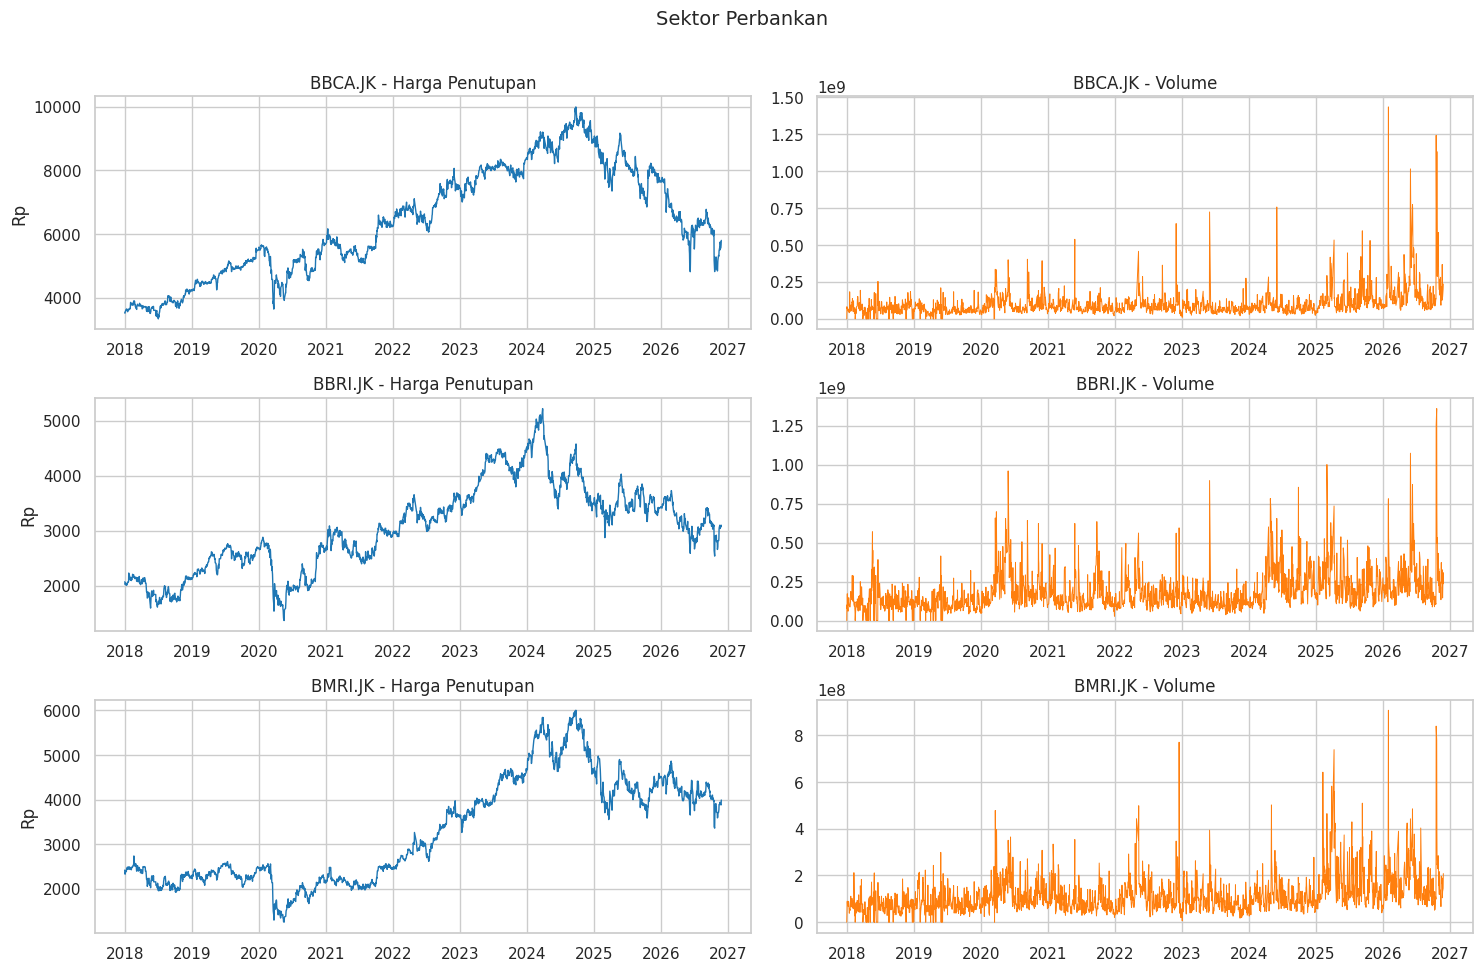

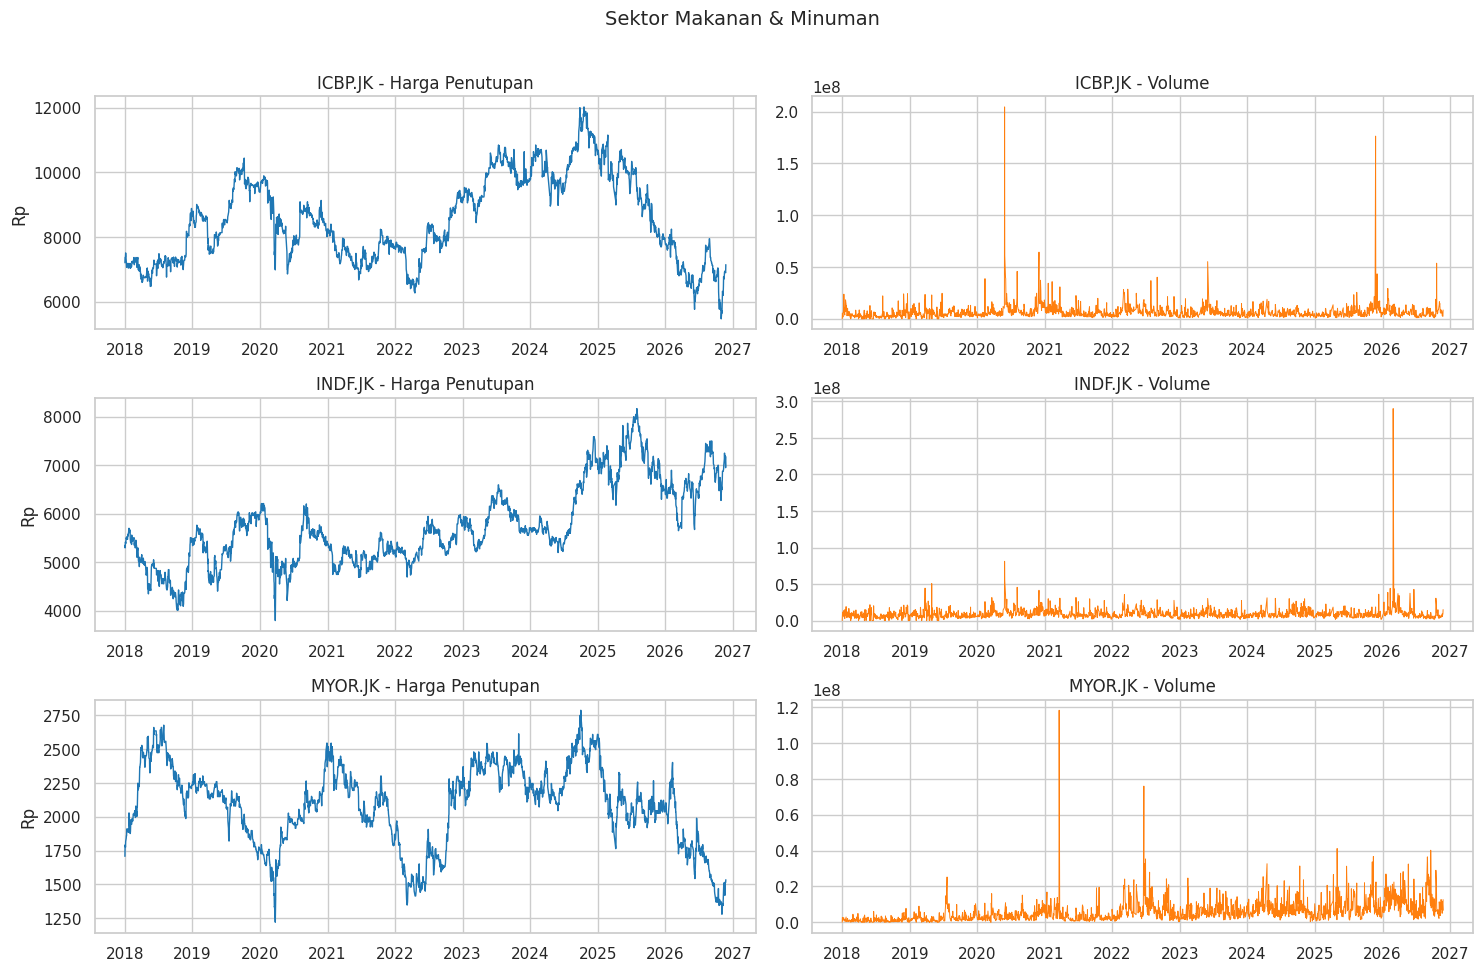

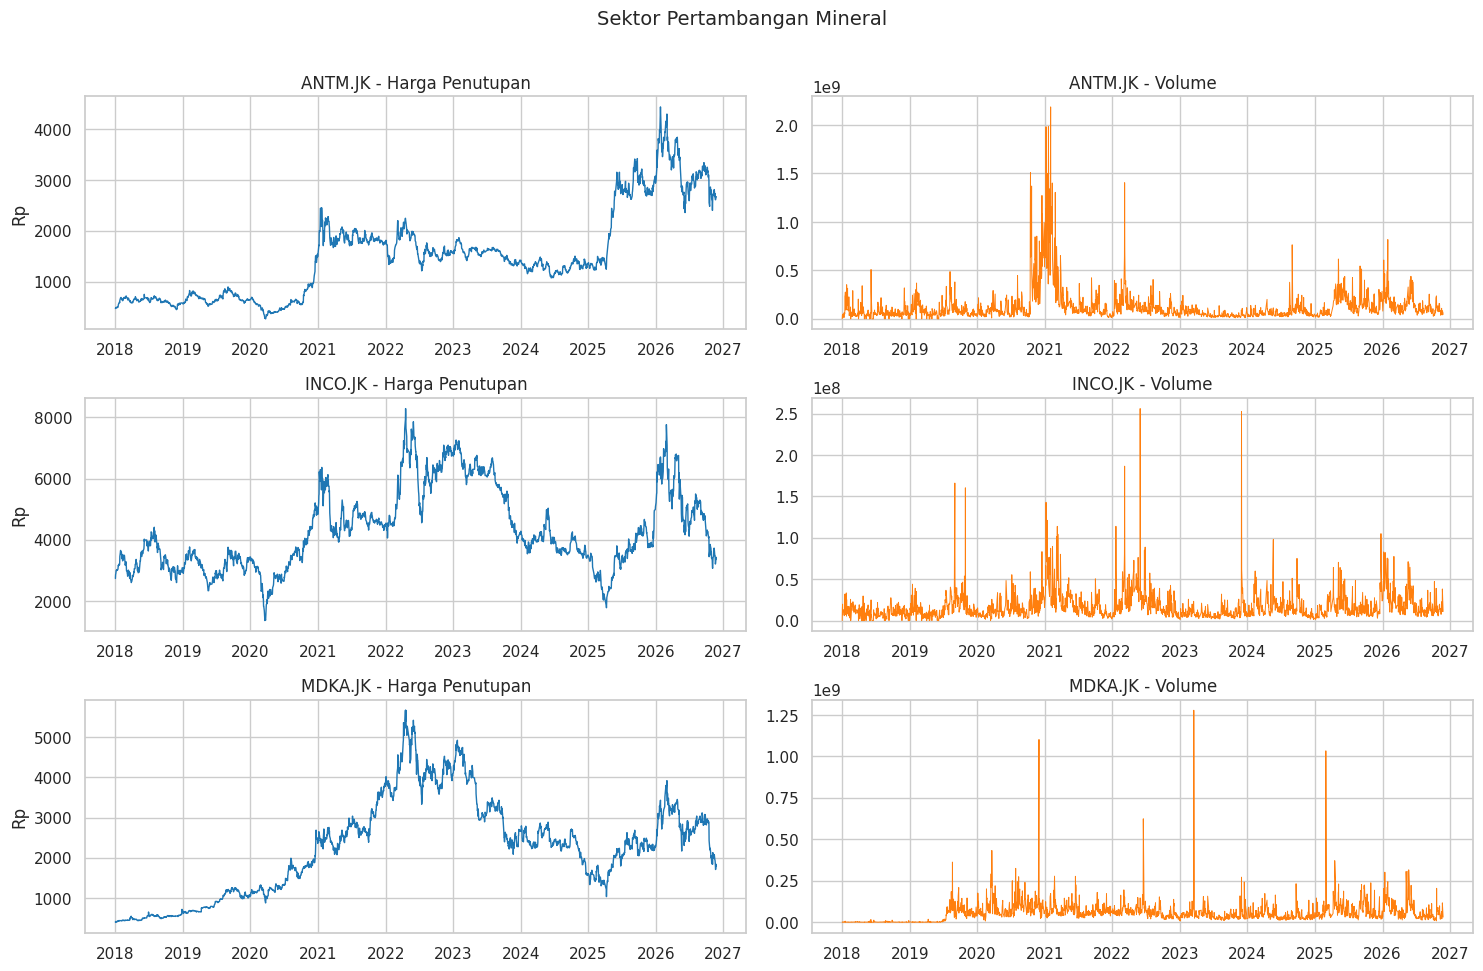

In [ ]:
# Grafik historis harga penutupan dan volume per sektor
for sector, tickers in SECTORS.items():
    tickers = [t for t in tickers if t in RAW]
    fig, axes = plt.subplots(len(tickers), 2, figsize=(15, 3.2 * len(tickers)), squeeze=False)
    for i, t in enumerate(tickers):
        df = RAW[t]
        axes[i, 0].plot(df.index, df["Close"], color="tab:blue", lw=1)
        axes[i, 0].set_title(f"{t} - Harga Penutupan")
        axes[i, 0].set_ylabel("Rp")
        axes[i, 1].plot(df.index, df["Volume"], color="tab:orange", lw=0.7)
        axes[i, 1].set_title(f"{t} - Volume")
    fig.suptitle(f"Sektor {sector}", fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()

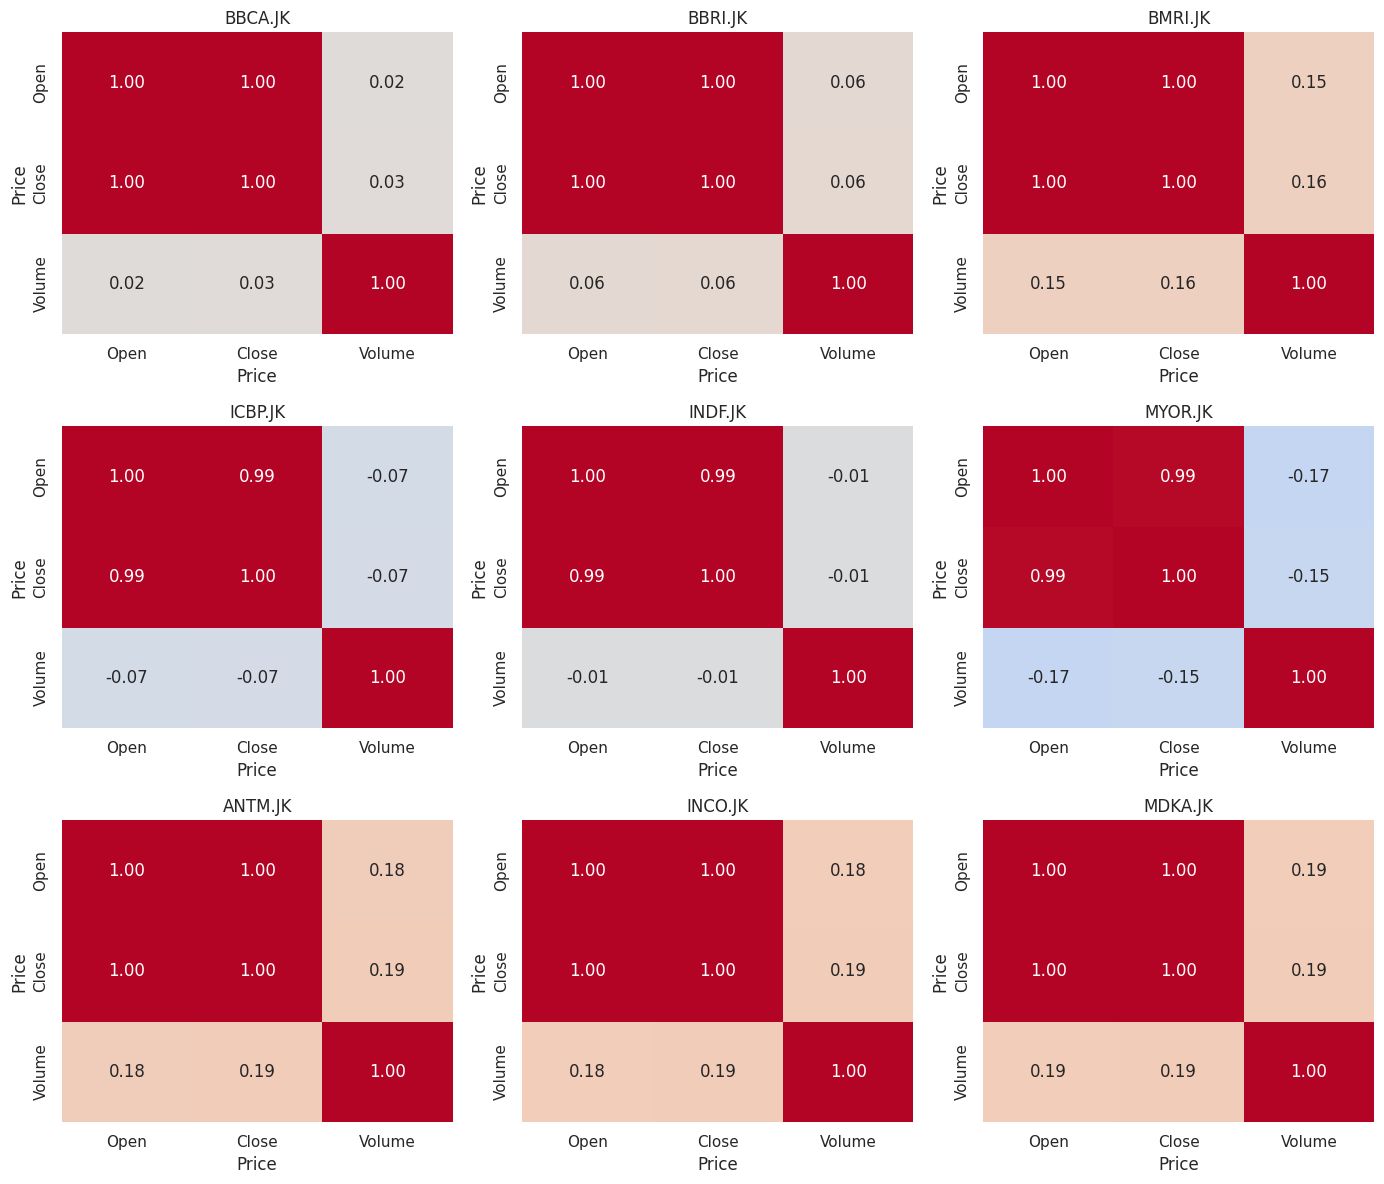

Statistik return harian:


,count,mean,std,min,25%,50%,75%,max
BBCA.JK,2180.0,0.0004,0.0168,-0.1481,-0.0082,0.0,0.0082,0.1733
BBRI.JK,2180.0,0.0004,0.0209,-0.1484,-0.0101,0.0,0.0102,0.2049
BMRI.JK,2180.0,0.0005,0.0213,-0.1482,-0.0103,0.0,0.0107,0.1580
ICBP.JK,2179.0,0.0002,0.0176,-0.0935,-0.0085,0.0,0.0085,0.1446
INDF.JK,2180.0,0.0003,0.0177,-0.0879,-0.0082,0.0,0.0097,0.1832
MYOR.JK,2180.0,0.0002,0.0205,-0.0877,-0.0104,0.0,0.0088,0.2112
ANTM.JK,2180.0,0.0013,0.0315,-0.1472,-0.0159,0.0,0.0154,0.2484
INCO.JK,2179.0,0.0006,0.0315,-0.1498,-0.0163,0.0,0.0147,0.1884
MDKA.JK,2180.0,0.0012,0.0329,-0.1495,-0.0147,0.0,0.0148,0.2477


In [ ]:
# Korelasi antar variabel dan statistik return harian
n = len(RAW)
cols = 3
rows_n = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(14, 4 * rows_n), squeeze=False)
for ax in axes.ravel():
    ax.axis("off")
for ax, (t, df) in zip(axes.ravel(), RAW.items()):
    ax.axis("on")
    sns.heatmap(df[["Open", "Close", "Volume"]].corr(), annot=True, fmt=".2f",
                cmap="coolwarm", vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(t)
plt.tight_layout()
plt.show()

ret_stats = pd.DataFrame({t: df["Close"].pct_change().describe() for t, df in RAW.items()}).T
print("Statistik return harian:")
display(ret_stats.round(4))

## 4. Data Preprocessing
Cleaning: urutkan tanggal, hapus duplikat, harga ≤ 0 dianggap tidak valid, missing value harga diisi **forward-fill** (hanya memakai data masa lalu), missing volume diisi 0.

In [ ]:
def clean_data(df):
    """Bersihkan data mentah satu saham."""
    df = df[["Open", "Close", "Volume"]].copy()
    df.index = pd.to_datetime(df.index).tz_localize(None)
    df = df[~df.index.duplicated(keep="last")].sort_index()
    df = df.apply(pd.to_numeric, errors="coerce")
    invalid = (df[["Open", "Close"]] <= 0).any(axis=1)
    df.loc[invalid, ["Open", "Close"]] = np.nan
    df[["Open", "Close"]] = df[["Open", "Close"]].ffill()
    df["Volume"] = df["Volume"].fillna(0)
    return df.dropna()


CLEAN = {}
for t, df in RAW.items():
    before = int(df[["Open", "Close", "Volume"]].isna().sum().sum())
    CLEAN[t] = clean_data(df)
    after = int(CLEAN[t].isna().sum().sum())
    print(f"{t:8s} missing sebelum={before:3d} sesudah={after} | baris {len(df)} -> {len(CLEAN[t])}")

BBCA.JK  missing sebelum=  0 sesudah=0 | baris 2181 -> 2181
BBRI.JK  missing sebelum=  0 sesudah=0 | baris 2181 -> 2181
BMRI.JK  missing sebelum=  0 sesudah=0 | baris 2181 -> 2181
ICBP.JK  missing sebelum=  0 sesudah=0 | baris 2180 -> 2180
INDF.JK  missing sebelum=  0 sesudah=0 | baris 2181 -> 2181
MYOR.JK  missing sebelum=  0 sesudah=0 | baris 2181 -> 2181
ANTM.JK  missing sebelum=  0 sesudah=0 | baris 2181 -> 2181
INCO.JK  missing sebelum=  0 sesudah=0 | baris 2180 -> 2180
MDKA.JK  missing sebelum=  0 sesudah=0 | baris 2181 -> 2181


## 5. Feature Engineering
Fitur tambahan (semua kausal, hanya memakai data sampai hari itu):
- `MA_7`, `MA_21`: rata-rata bergerak Close
- `Return`: perubahan persentase harian Close
- `Volume` ditransformasi `log1p` karena distribusinya sangat miring

Sequence dibentuk sehingga **fitur hari t-60 … t-1 memprediksi Close hari t**.

In [ ]:
def add_features(df):
    d = df.copy()
    d["MA_7"] = d["Close"].rolling(7).mean()
    d["MA_21"] = d["Close"].rolling(21).mean()
    d["Return"] = d["Close"].pct_change()
    d["Volume"] = np.log1p(d["Volume"])
    return d.dropna()


def make_sequences(X, y, window):
    """X[i-window:i] -> y[i]. Mengembalikan X_seq, y_seq, indeks target."""
    Xs, ys = [], []
    for i in range(window, len(X)):
        Xs.append(X[i - window:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys), np.arange(window, len(X))


DATA = {t: add_features(df) for t, df in CLEAN.items()}
display(DATA[next(iter(DATA))].tail())

Price,Open,Close,Volume,MA_7,MA_21,Return
Date,,,,,,
2026-11-18,5600.0,5750.0,19.723000,5492.857143,5207.619048,0.045455
2026-11-19,5675.0,5650.0,18.820752,5542.857143,5225.476190,-0.017391
2026-11-20,5600.0,5550.0,18.810268,5575.000000,5243.333333,-0.017699
2026-11-23,5475.0,5675.0,19.117968,5603.571429,5274.285714,0.022523
2026-11-24,5775.0,5800.0,19.277796,5646.428571,5315.238095,0.022026


## 6. Pembagian Dataset (Kronologis, Tanpa Leakage)
- 80% data pertama = train, 20% terakhir = test (tidak diacak).
- 10% bagian akhir sequence train = validasi.
- Scaler di-fit **hanya** pada baris train. Sequence test memakai 60 hari sebelumnya sebagai input (termasuk akhir train), yang sah karena itu data historis yang memang sudah diketahui.

,Total baris,Train seq,Val seq,Test seq,Batas train/test
BBCA.JK,2161,1502,166,433,2025-01-31
BBRI.JK,2161,1502,166,433,2025-01-31
BMRI.JK,2161,1502,166,433,2025-01-31
ICBP.JK,2160,1502,166,432,2025-02-03
INDF.JK,2161,1502,166,433,2025-01-31
MYOR.JK,2161,1502,166,433,2025-01-31
ANTM.JK,2161,1502,166,433,2025-01-31
INCO.JK,2160,1502,166,432,2025-02-03
MDKA.JK,2161,1502,166,433,2025-01-31


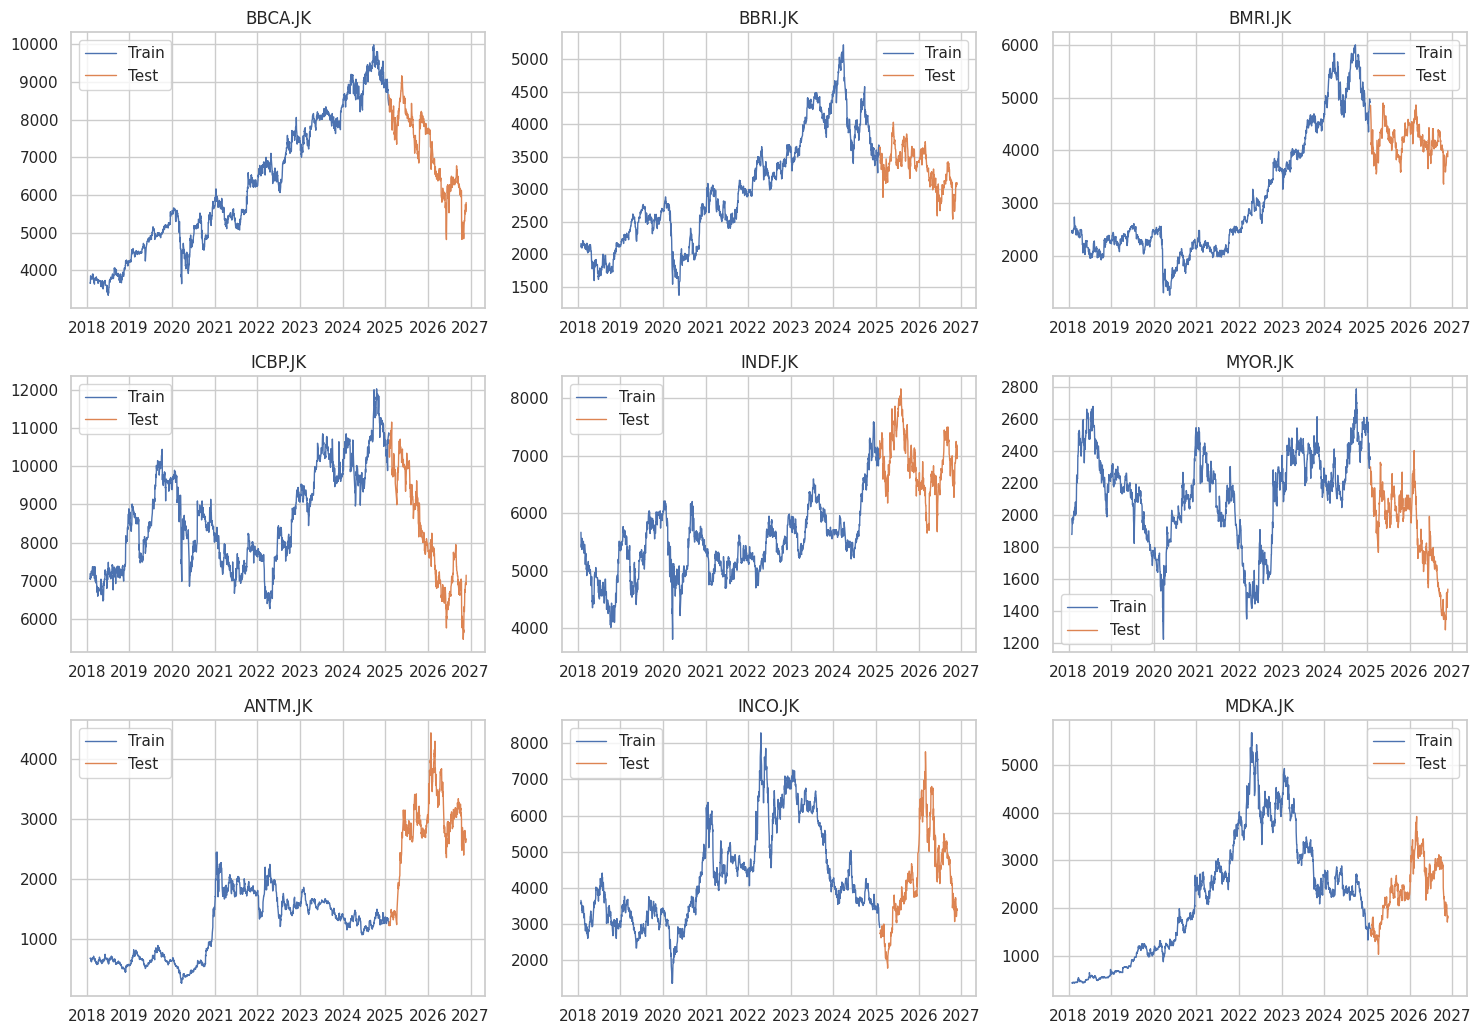

In [ ]:
def prepare_data(df):
    n = len(df)
    n_train = int(n * TRAIN_RATIO)

    feat_scaler = MinMaxScaler().fit(df[FEATURES].iloc[:n_train])
    tgt_scaler = MinMaxScaler().fit(df[[TARGET]].iloc[:n_train])

    X_all = feat_scaler.transform(df[FEATURES])
    y_all = tgt_scaler.transform(df[[TARGET]]).ravel()

    X_seq, y_seq, idx = make_sequences(X_all, y_all, WINDOW)
    train_mask = idx < n_train
    test_mask = ~train_mask

    X_tr_full, y_tr_full = X_seq[train_mask], y_seq[train_mask]
    n_val = int(len(X_tr_full) * VAL_RATIO)
    n_fit = len(X_tr_full) - n_val

    return {
        "X_train": X_tr_full[:n_fit], "y_train": y_tr_full[:n_fit],
        "X_val": X_tr_full[n_fit:], "y_val": y_tr_full[n_fit:],
        "X_test": X_seq[test_mask], "y_test": y_seq[test_mask],
        "test_idx": idx[test_mask],
        "dates_test": df.index[idx[test_mask]],
        "feat_scaler": feat_scaler, "tgt_scaler": tgt_scaler,
        "X_last": X_all[-WINDOW:],           # jendela terakhir untuk prediksi hari berikutnya
        "n_train_rows": n_train,
    }


PREP = {t: prepare_data(df) for t, df in DATA.items()}

split_df = pd.DataFrame({
    t: {"Total baris": len(DATA[t]), "Train seq": len(p["X_train"]),
        "Val seq": len(p["X_val"]), "Test seq": len(p["X_test"]),
        "Batas train/test": DATA[t].index[p["n_train_rows"]].date()}
    for t, p in PREP.items()}).T
display(split_df)

# Visualisasi pembagian data
n = len(PREP)
cols = 3
rows_n = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(15, 3.5 * rows_n), squeeze=False)
for ax in axes.ravel():
    ax.axis("off")
for ax, t in zip(axes.ravel(), PREP):
    ax.axis("on")
    d = DATA[t]
    k = PREP[t]["n_train_rows"]
    ax.plot(d.index[:k], d["Close"].iloc[:k], label="Train", lw=1)
    ax.plot(d.index[k:], d["Close"].iloc[k:], label="Test", lw=1)
    ax.set_title(t)
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Pembuatan Model LSTM
Arsitektur: `Input → LSTM(64) → Dropout(0.2) → LSTM(32) → Dropout(0.2) → Dense(16, relu) → Dense(1)`

## 8. Pembuatan Model BiLSTM
Arsitektur identik, hanya setiap layer LSTM dibungkus `Bidirectional`. Seed, optimizer, loss, dan hyperparameter sama agar perbandingan adil.

In [ ]:
def build_model(kind, window=WINDOW, n_features=len(FEATURES)):
    """Bangun model 'LSTM' atau 'BiLSTM' dengan konfigurasi yang konsisten."""
    assert kind in ("LSTM", "BiLSTM")
    set_seed()

    def rnn(units, return_sequences):
        layer = LSTM(units, return_sequences=return_sequences)
        return Bidirectional(layer) if kind == "BiLSTM" else layer

    model = Sequential([
        Input(shape=(window, n_features)),
        rnn(64, True),
        Dropout(0.2),
        rnn(32, False),
        Dropout(0.2),
        Dense(16, activation="relu"),
        Dense(1),
    ], name=kind)
    model.compile(optimizer=tf.keras.optimizers.Adam(LEARNING_RATE), loss="mse")
    return model


for k in ("LSTM", "BiLSTM"):
    m = build_model(k)
    print(f"=== {k}: {m.count_params():,} parameter ===")
    m.summary()

=== LSTM: 31,137 parameter ===


Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,137 (121.63 KB)

 Trainable params: 31,137 (121.63 KB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 60, 128)        │        36,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 78,625 (307.13 KB)

 Trainable params: 78,625 (307.13 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Training Model
Setiap perusahaan dilatih dengan model LSTM dan BiLSTM terpisah. `EarlyStopping` memantau `val_loss` (bukan data test) dan mengembalikan bobot terbaik.

In [ ]:
def compute_metrics(y_true, y_pred):
    """Metrik dalam skala harga asli."""
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = float(np.sqrt(mse))
    mape = float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100)
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "MAPE (%)": mape}


RESULTS, PRED, MODELS, HIST = [], {}, {}, {}

for ticker, d in PREP.items():
    sector = SECTOR_OF[ticker]
    tgt = d["tgt_scaler"]
    y_true = tgt.inverse_transform(d["y_test"].reshape(-1, 1)).ravel()
    PRED[ticker] = {"dates": d["dates_test"], "Actual": y_true}

    # Baseline naif: harga penutupan kemarin
    naive = DATA[ticker][TARGET].values[d["test_idx"] - 1]
    PRED[ticker]["Naive"] = naive
    RESULTS.append({"Sektor": sector, "Ticker": ticker, "Model": "Naive (kemarin)",
                    **compute_metrics(y_true, naive)})

    MODELS[ticker], HIST[ticker] = {}, {}
    for kind in ("LSTM", "BiLSTM"):
        t0 = time.time()
        model = build_model(kind)
        es = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
        h = model.fit(d["X_train"], d["y_train"],
                      validation_data=(d["X_val"], d["y_val"]),
                      epochs=EPOCHS, batch_size=BATCH_SIZE,
                      callbacks=[es], verbose=0)
        pred = tgt.inverse_transform(model.predict(d["X_test"], verbose=0)).ravel()

        PRED[ticker][kind] = pred
        MODELS[ticker][kind] = model
        HIST[ticker][kind] = h.history
        RESULTS.append({"Sektor": sector, "Ticker": ticker, "Model": kind,
                        **compute_metrics(y_true, pred)})
        print(f"{ticker:8s} {kind:7s} epoch={len(h.history['loss']):2d} "
              f"val_loss={min(h.history['val_loss']):.5f} waktu={time.time() - t0:5.1f}s")

BBCA.JK  LSTM    epoch=25 val_loss=0.00088 waktu= 82.1s
BBCA.JK  BiLSTM  epoch=18 val_loss=0.00209 waktu=106.3s
BBRI.JK  LSTM    epoch=29 val_loss=0.00066 waktu= 85.7s
BBRI.JK  BiLSTM  epoch=40 val_loss=0.00048 waktu=240.0s
BMRI.JK  LSTM    epoch=39 val_loss=0.00078 waktu=107.8s
BMRI.JK  BiLSTM  epoch=19 val_loss=0.00137 waktu=123.2s
ICBP.JK  LSTM    epoch=26 val_loss=0.00198 waktu= 73.7s
ICBP.JK  BiLSTM  epoch=21 val_loss=0.00336 waktu=142.4s
INDF.JK  LSTM    epoch=33 val_loss=0.00145 waktu= 93.2s
INDF.JK  BiLSTM  epoch=12 val_loss=0.00270 waktu= 72.0s
MYOR.JK  LSTM    epoch=12 val_loss=0.00385 waktu= 34.4s
MYOR.JK  BiLSTM  epoch=16 val_loss=0.00290 waktu=111.7s
ANTM.JK  LSTM    epoch=34 val_loss=0.00028 waktu= 92.9s
ANTM.JK  BiLSTM  epoch=21 val_loss=0.00026 waktu=131.1s
INCO.JK  LSTM    epoch=34 val_loss=0.00018 waktu= 95.3s
INCO.JK  BiLSTM  epoch=28 val_loss=0.00014 waktu=176.2s
MDKA.JK  LSTM    epoch=50 val_loss=0.00018 waktu=130.7s
MDKA.JK  BiLSTM  epoch=20 val_loss=0.00029 waktu

## 10. Evaluasi Model
Semua metrik dihitung pada **data test** dalam skala harga asli (Rupiah).

In [ ]:
results_df = pd.DataFrame(RESULTS)
METRICS = ["MAE", "MSE", "RMSE", "MAPE (%)"]

print("Tabel evaluasi per perusahaan:")
display(results_df.sort_values(["Sektor", "Ticker", "Model"]).reset_index(drop=True).round(4))

print("\nRata-rata per sektor:")
sector_df = results_df.groupby(["Sektor", "Model"])[METRICS].mean().round(4)
display(sector_df)

Tabel evaluasi per perusahaan:


,Sektor,Ticker,Model,MAE,MSE,RMSE,MAPE (%)
0,Makanan & Minuman,ICBP.JK,BiLSTM,165.4012,51182.3998,226.2353,2.0948
1,Makanan & Minuman,ICBP.JK,LSTM,186.4108,65184.7181,255.3130,2.4259
2,Makanan & Minuman,ICBP.JK,Naive (kemarin),117.2426,26122.2667,161.6238,1.4574
3,Makanan & Minuman,INDF.JK,BiLSTM,195.8802,58667.7234,242.2142,2.8063
4,Makanan & Minuman,INDF.JK,LSTM,152.6956,35180.5384,187.5648,2.2047
5,Makanan & Minuman,INDF.JK,Naive (kemarin),93.5940,15443.4411,124.2716,1.3680
6,Makanan & Minuman,MYOR.JK,BiLSTM,47.9644,4089.5144,63.9493,2.5373
7,Makanan & Minuman,MYOR.JK,LSTM,80.5908,9863.6582,99.3160,4.3577
8,Makanan & Minuman,MYOR.JK,Naive (kemarin),33.1394,2117.9944,46.0217,1.7363
9,Perbankan,BBCA.JK,BiLSTM,180.3187,58147.4519,241.1378,2.6588



Rata-rata per sektor:


MAE         MSE      RMSE  MAPE (%)
Sektor               Model                                                    
Makanan & Minuman    BiLSTM           136.4153  37979.8792  177.4663    2.4795
                     LSTM             139.8991  36742.9716  180.7312    2.9961
                     Naive (kemarin)   81.3254  14561.2340  110.6391    1.5206
Perbankan            BiLSTM           119.0257  29639.5701  159.0316    2.4300
                     LSTM             133.1560  35506.0346  173.1217    2.6878
                     Naive (kemarin)   75.7055  12293.8198  106.4423    1.6013
Pertambangan Mineral BiLSTM           161.6720  45878.9314  209.0478    5.1199
                     LSTM             209.1716  79666.3935  258.3371    6.4722
                     Naive (kemarin)   94.5585  19548.5974  133.6896    2.9744

## 11. Visualisasi Hasil

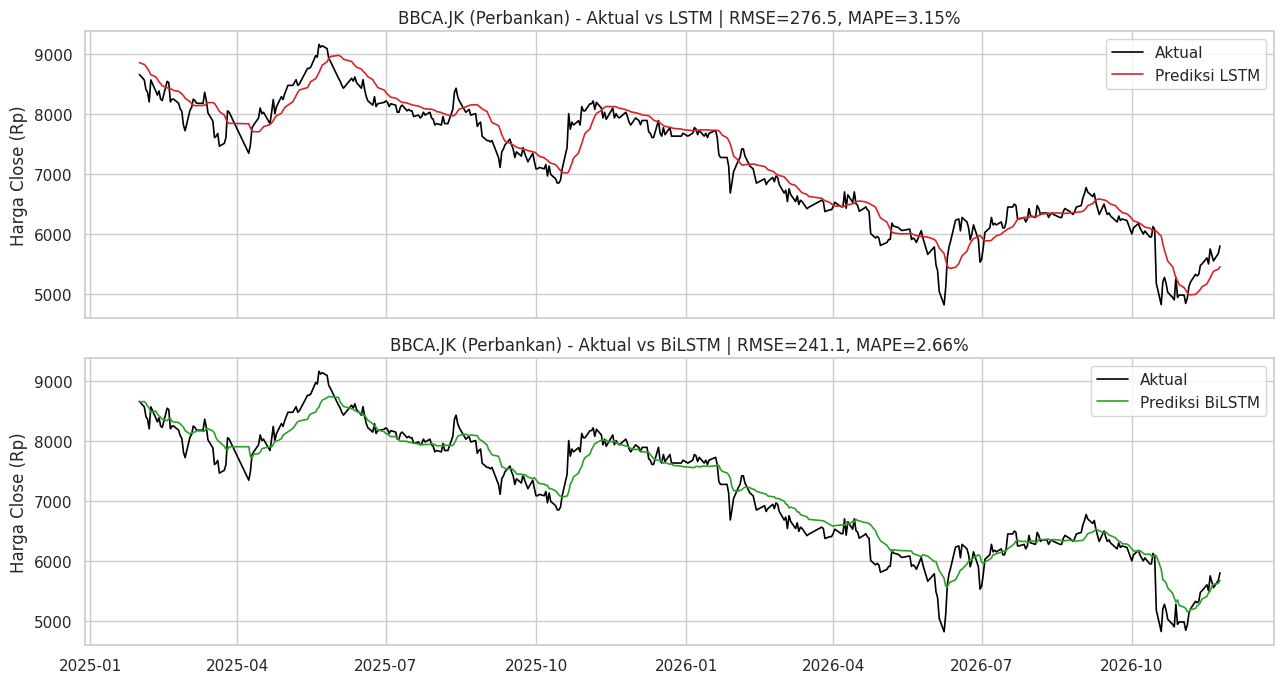

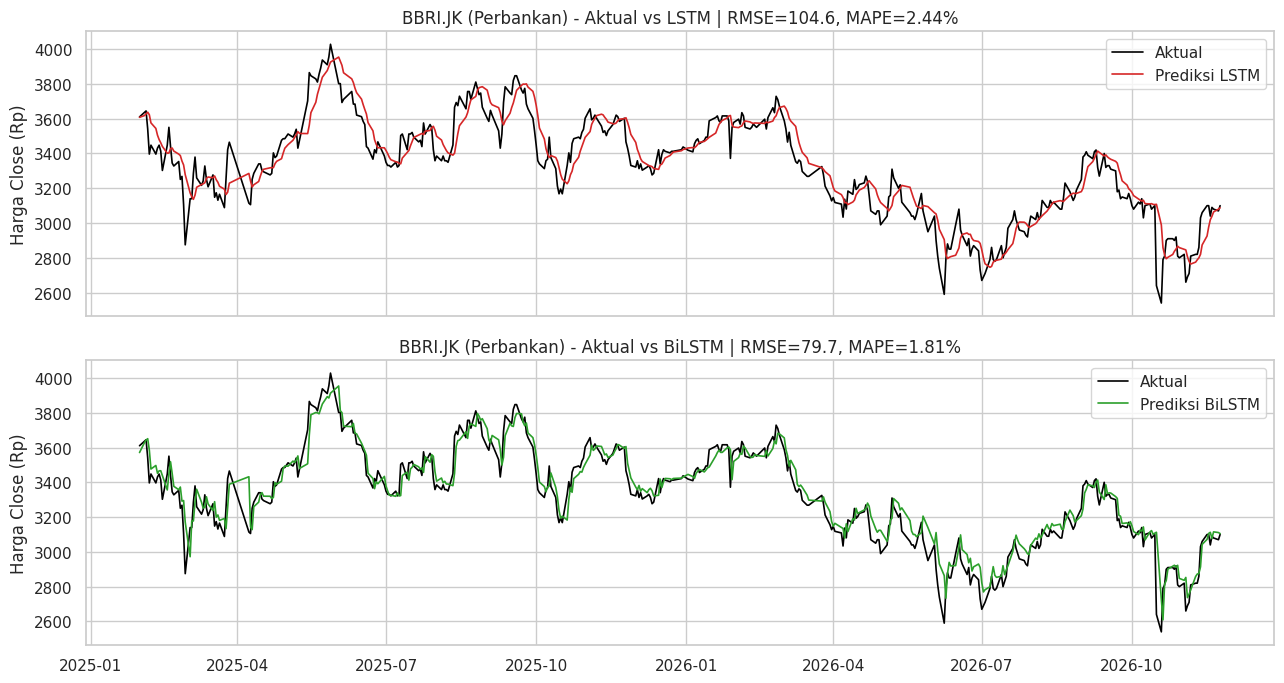

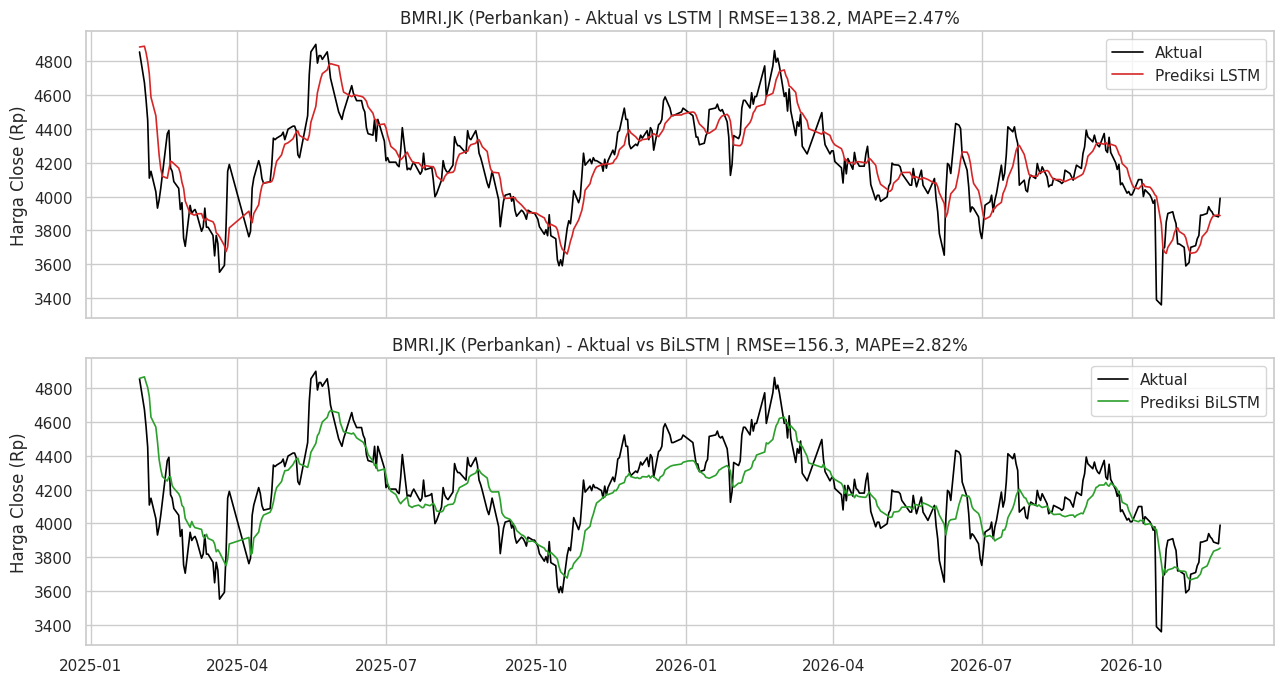

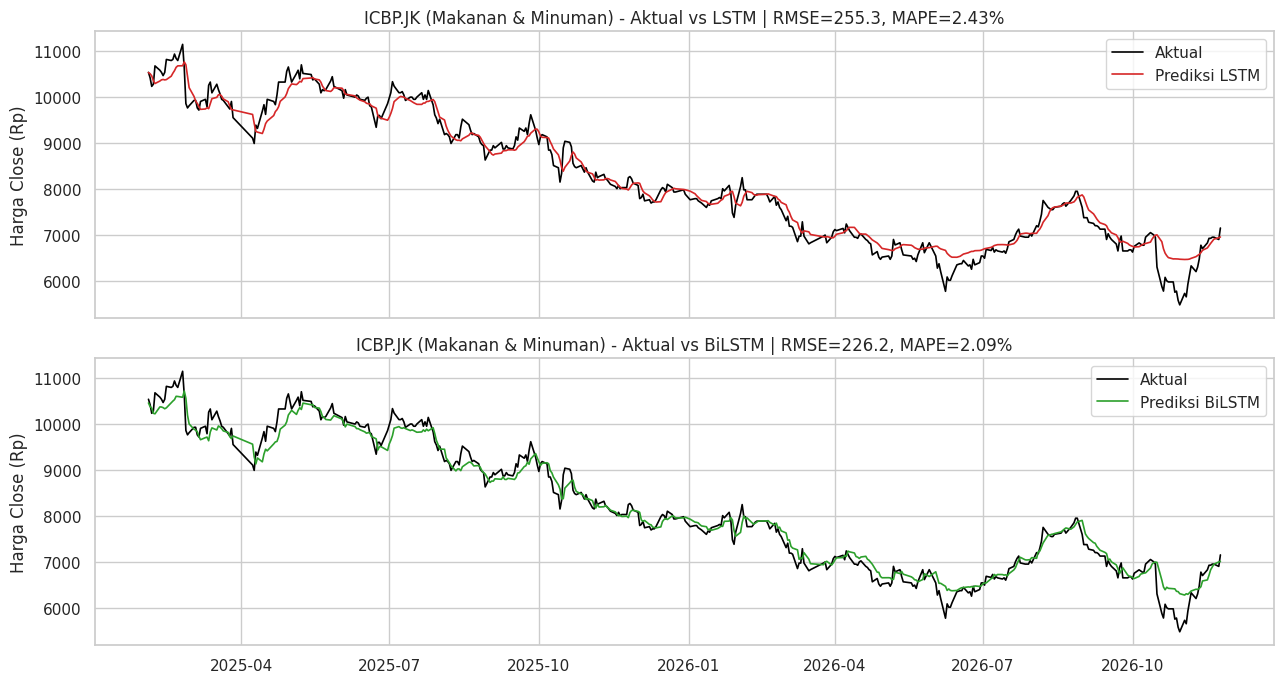

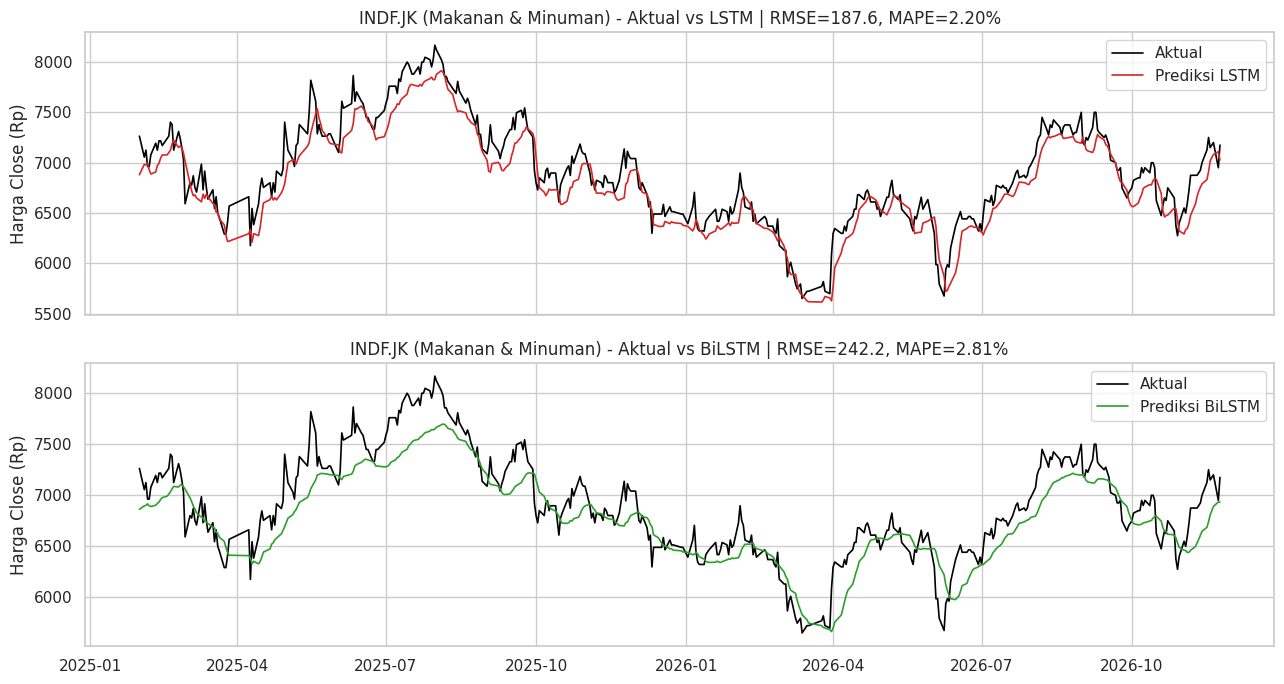

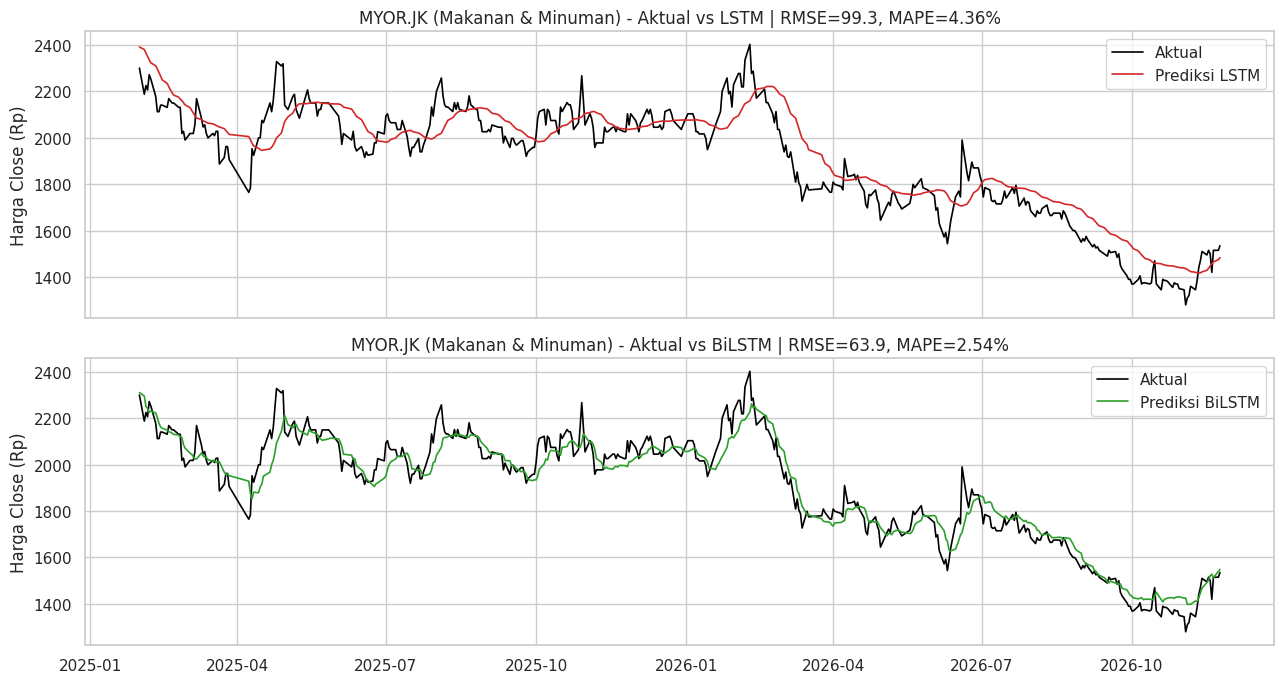

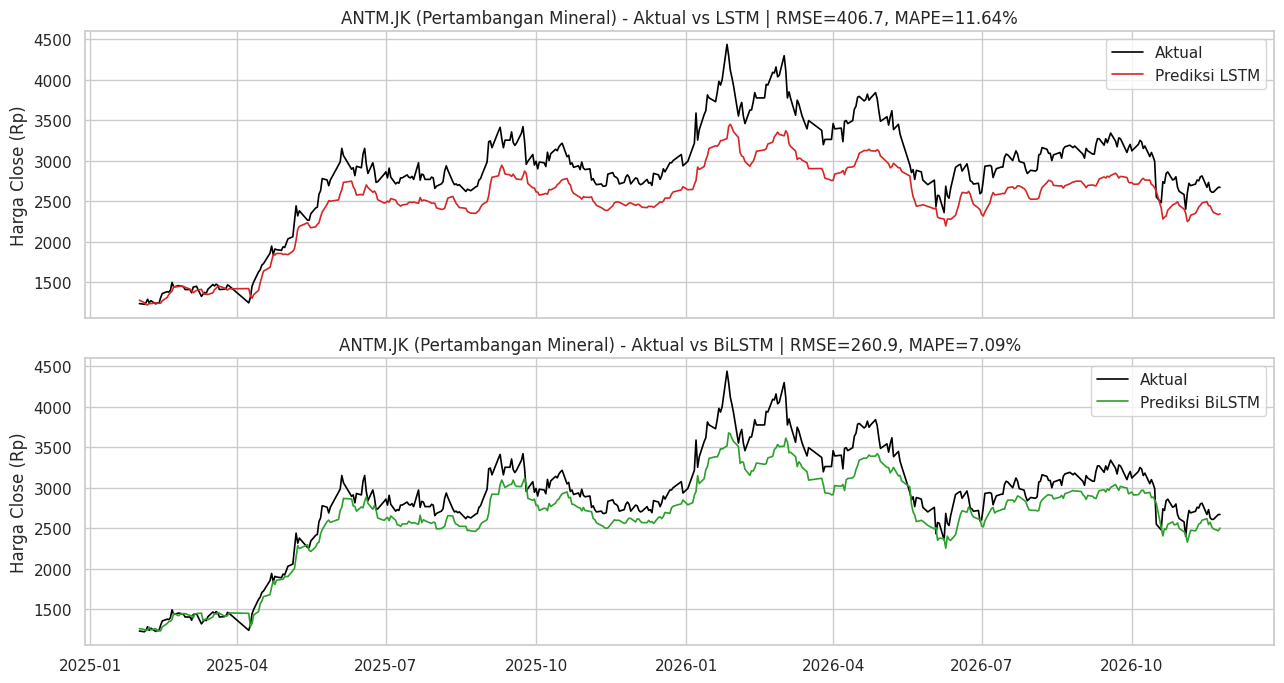

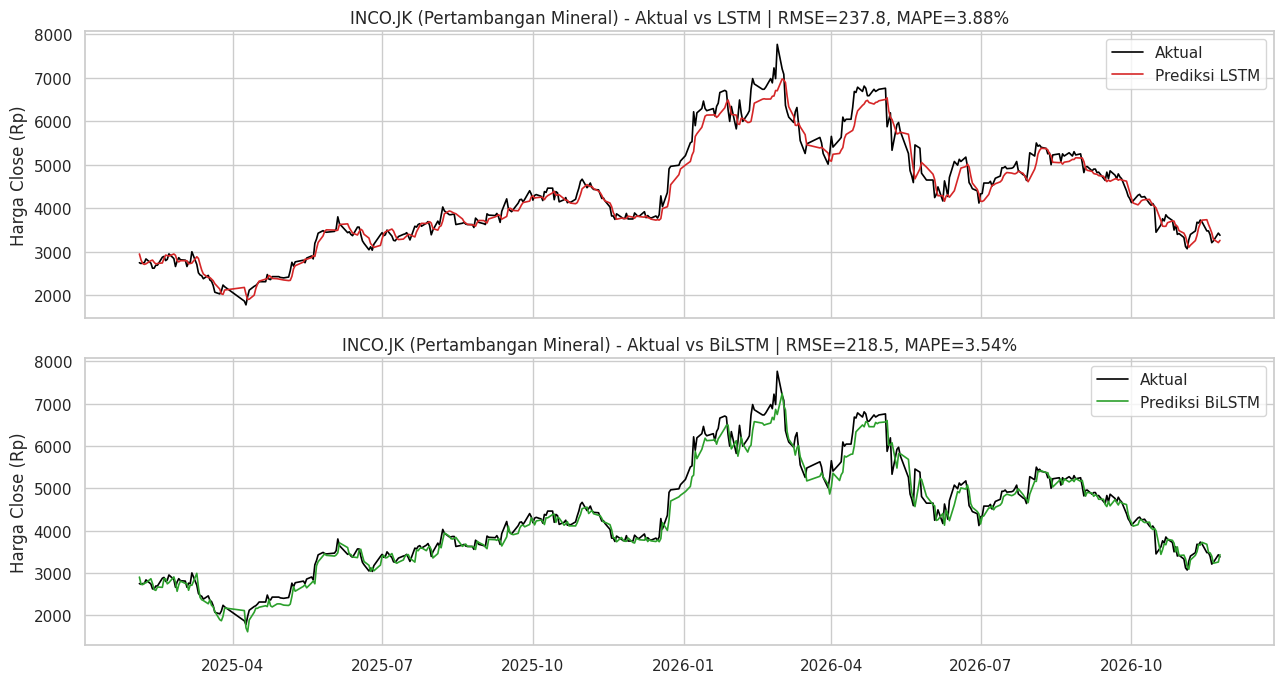

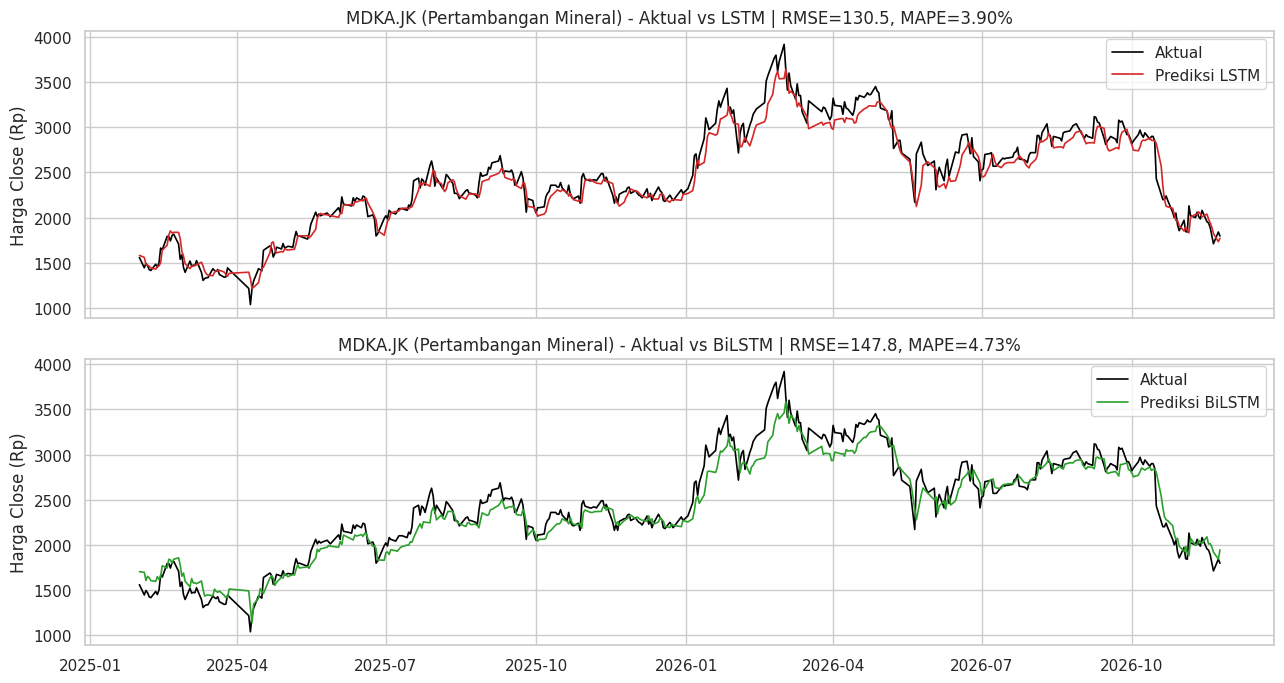

In [ ]:
# Aktual vs prediksi LSTM dan BiLSTM per perusahaan
for ticker, p in PRED.items():
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    for ax, kind, color in zip(axes, ("LSTM", "BiLSTM"), ("tab:red", "tab:green")):
        ax.plot(p["dates"], p["Actual"], label="Aktual", color="black", lw=1.2)
        ax.plot(p["dates"], p[kind], label=f"Prediksi {kind}", color=color, lw=1.2)
        m = results_df[(results_df.Ticker == ticker) & (results_df.Model == kind)].iloc[0]
        ax.set_title(f"{ticker} ({SECTOR_OF[ticker]}) - Aktual vs {kind} "
                     f"| RMSE={m['RMSE']:.1f}, MAPE={m['MAPE (%)']:.2f}%")
        ax.set_ylabel("Harga Close (Rp)")
        ax.legend()
    plt.tight_layout()
    plt.show()

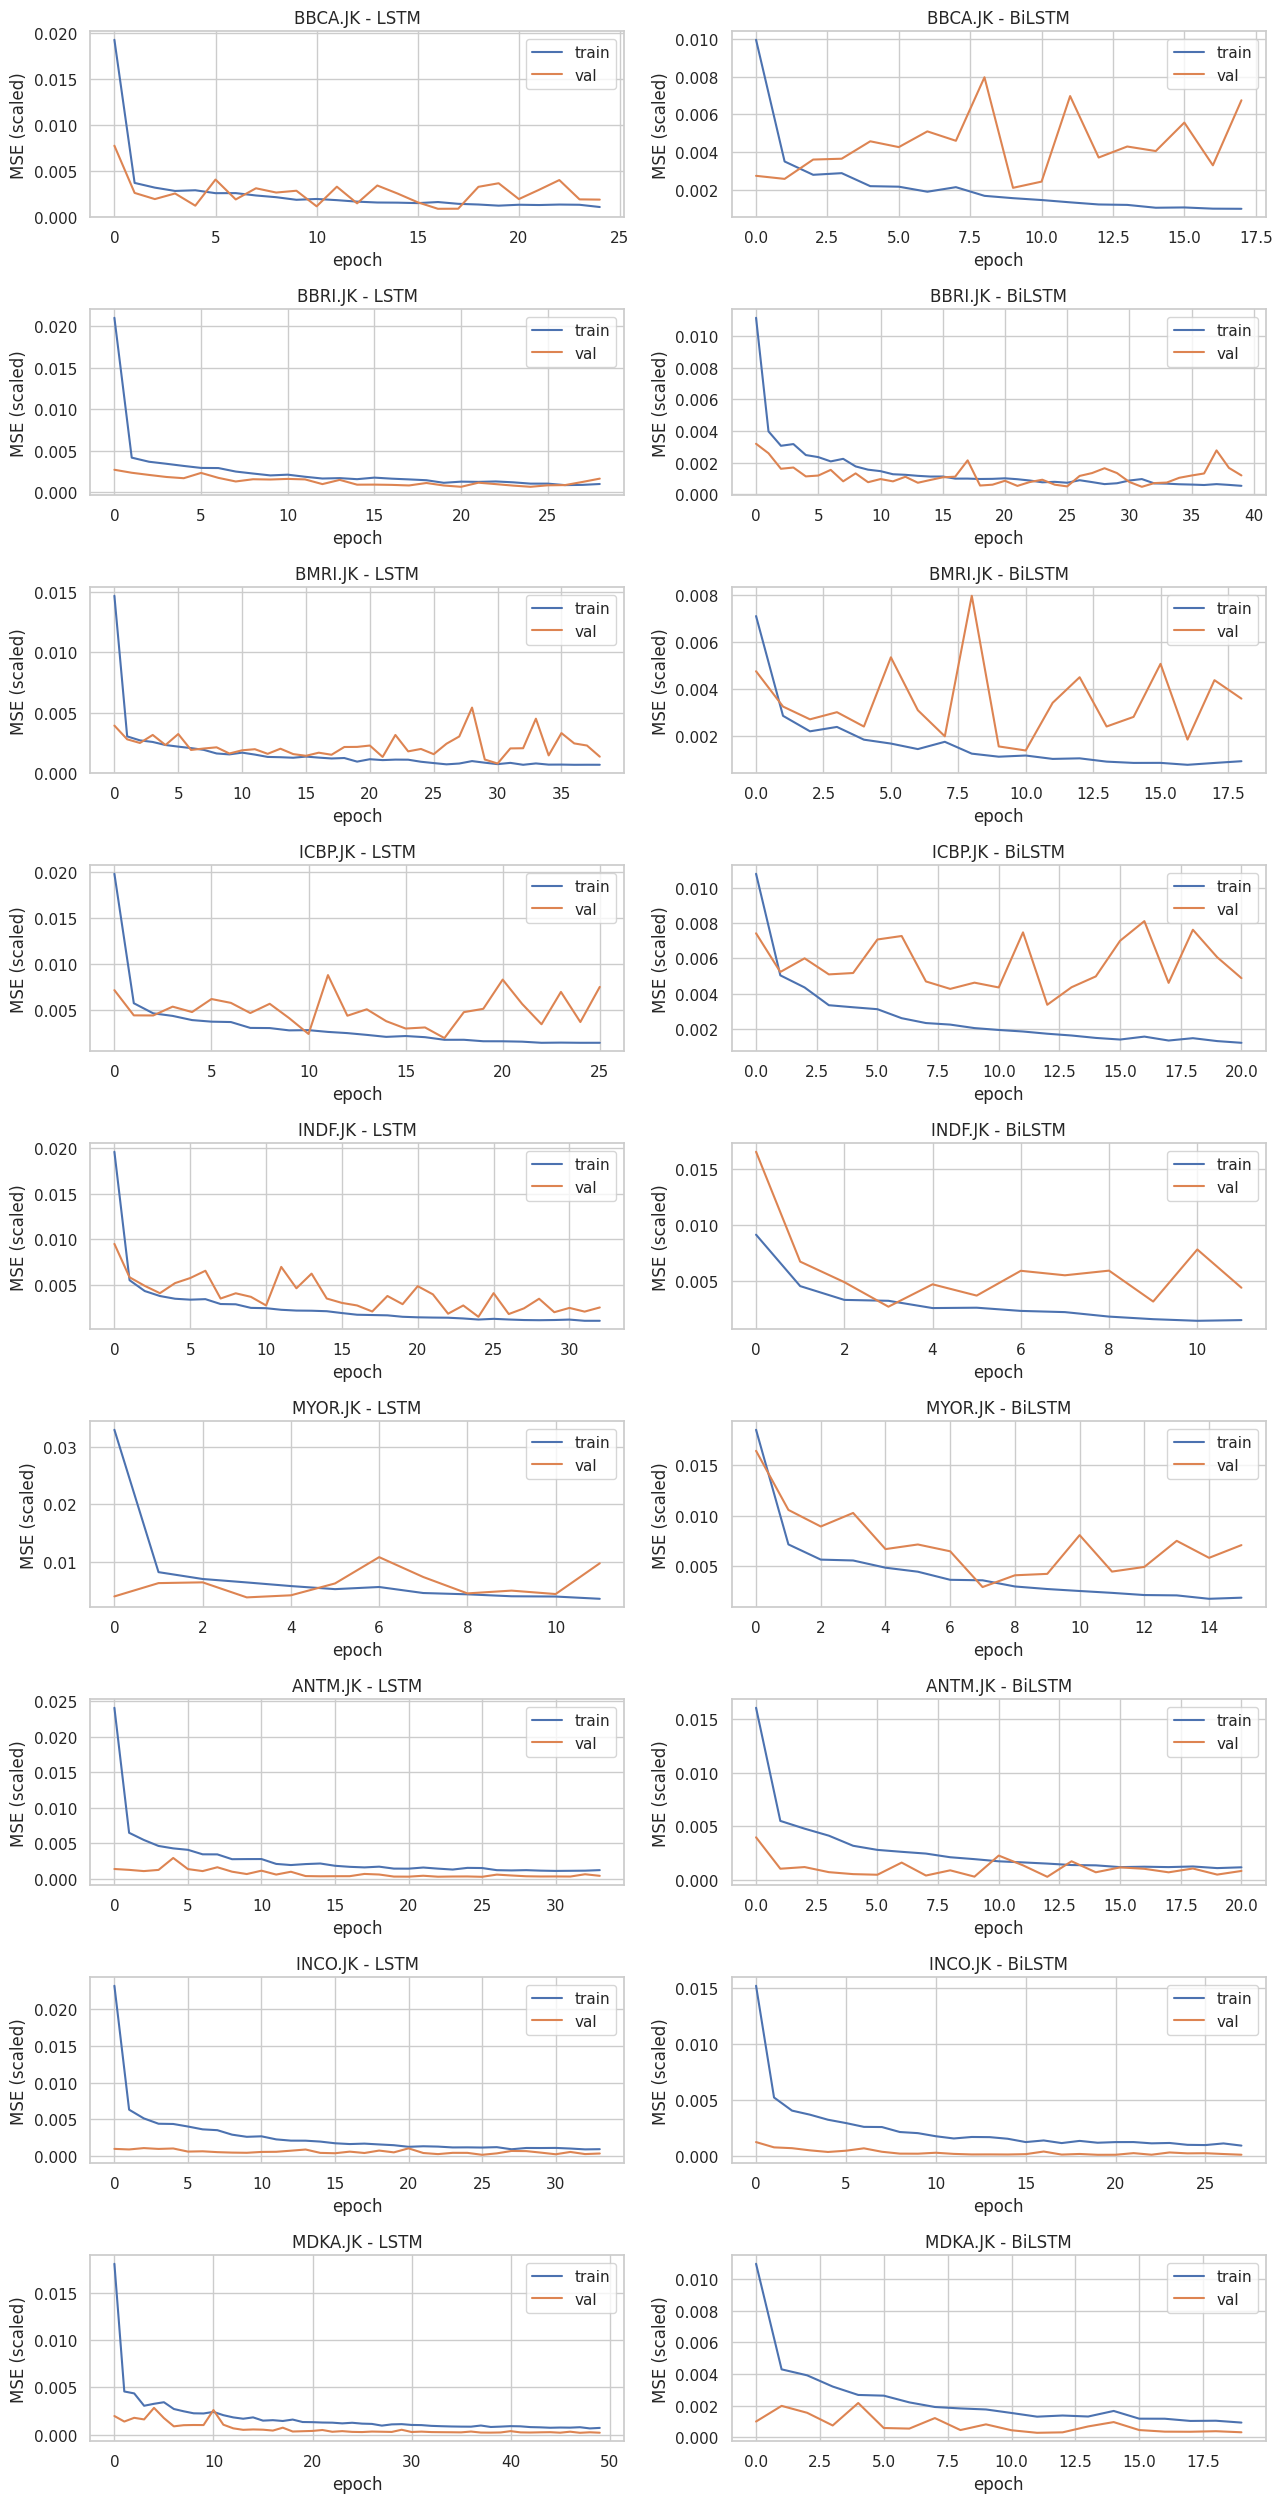

In [ ]:
# Kurva loss training
n = len(HIST)
fig, axes = plt.subplots(n, 2, figsize=(13, 2.8 * n), squeeze=False)
for i, (ticker, hh) in enumerate(HIST.items()):
    for j, kind in enumerate(("LSTM", "BiLSTM")):
        axes[i, j].plot(hh[kind]["loss"], label="train")
        axes[i, j].plot(hh[kind]["val_loss"], label="val")
        axes[i, j].set_title(f"{ticker} - {kind}")
        axes[i, j].set_xlabel("epoch")
        axes[i, j].set_ylabel("MSE (scaled)")
        axes[i, j].legend()
plt.tight_layout()
plt.show()

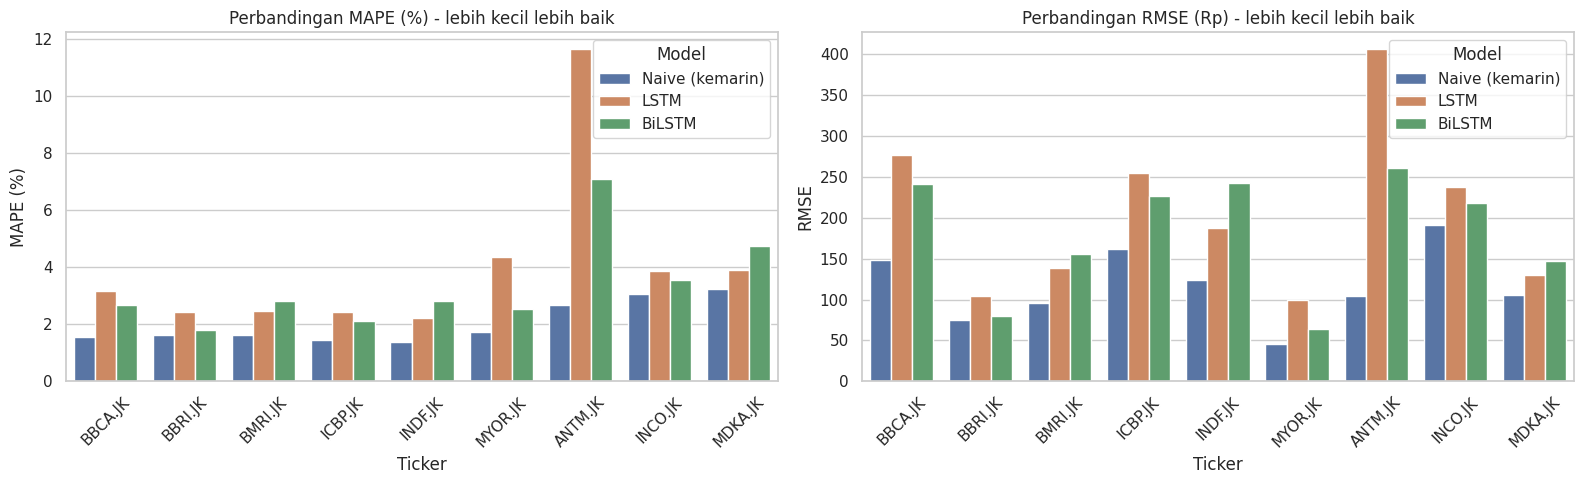

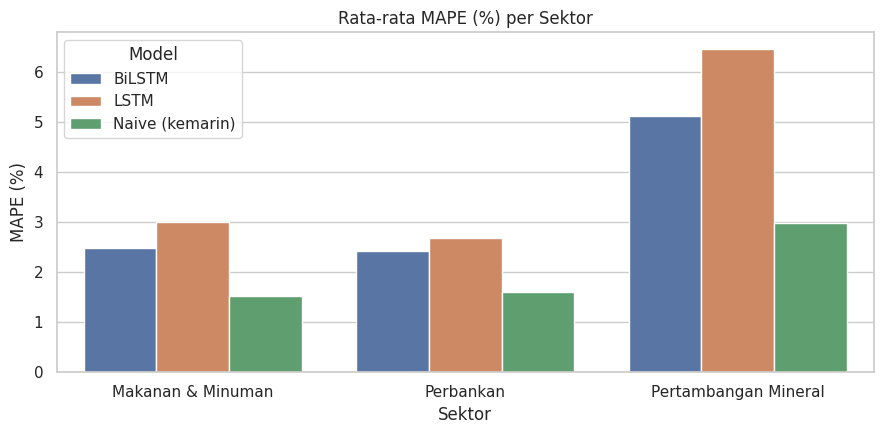

In [ ]:
# Perbandingan performa kedua model (plus baseline)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=results_df, x="Ticker", y="MAPE (%)", hue="Model", ax=axes[0])
axes[0].set_title("Perbandingan MAPE (%) - lebih kecil lebih baik")
axes[0].tick_params(axis="x", rotation=45)
sns.barplot(data=results_df, x="Ticker", y="RMSE", hue="Model", ax=axes[1])
axes[1].set_title("Perbandingan RMSE (Rp) - lebih kecil lebih baik")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

# Perbandingan rata-rata per sektor
sec_plot = results_df.groupby(["Sektor", "Model"])["MAPE (%)"].mean().reset_index()
plt.figure(figsize=(9, 4.5))
sns.barplot(data=sec_plot, x="Sektor", y="MAPE (%)", hue="Model")
plt.title("Rata-rata MAPE (%) per Sektor")
plt.tight_layout()
plt.show()

### Prediksi Harga Penutupan Periode Berikutnya
Jendela 60 hari terakhir dipakai untuk memprediksi Close hari bursa berikutnya. Tanggal berikutnya dihitung sebagai hari kerja berikutnya (tidak memperhitungkan hari libur BEI).

In [ ]:
def predict_next_day(ticker):
    d, df = PREP[ticker], DATA[ticker]
    x = d["X_last"][np.newaxis, ...]
    out = {"Sektor": SECTOR_OF[ticker], "Ticker": ticker,
           "Tanggal Terakhir": df.index[-1].date(),
           "Prediksi Untuk": pd.bdate_range(df.index[-1] + pd.Timedelta(days=1), periods=1)[0].date(),
           "Close Terakhir": float(df[TARGET].iloc[-1])}
    for kind in ("LSTM", "BiLSTM"):
        p = MODELS[ticker][kind].predict(x, verbose=0)
        out[f"Prediksi {kind}"] = float(d["tgt_scaler"].inverse_transform(p)[0, 0])
    out["Selisih |LSTM-BiLSTM|"] = abs(out["Prediksi LSTM"] - out["Prediksi BiLSTM"])
    return out


next_df = pd.DataFrame([predict_next_day(t) for t in PREP])
display(next_df.round(2))
print("CATATAN: angka di atas adalah estimasi berdasarkan pola historis, "
      "bukan jaminan harga saham di masa depan dan bukan saran investasi.")

,Sektor,Ticker,Tanggal Terakhir,Prediksi Untuk,Close Terakhir,Prediksi LSTM,Prediksi BiLSTM,Selisih |LSTM-BiLSTM|
0,Perbankan,BBCA.JK,2026-11-24,2026-11-25,5800.0,5499.53,5738.62,239.09
1,Perbankan,BBRI.JK,2026-11-24,2026-11-25,3100.0,3099.85,3135.67,35.82
2,Perbankan,BMRI.JK,2026-11-24,2026-11-25,3990.0,3911.91,3893.42,18.49
3,Makanan & Minuman,ICBP.JK,2026-11-24,2026-11-25,7150.0,7019.46,7177.15,157.69
4,Makanan & Minuman,INDF.JK,2026-11-24,2026-11-25,7175.0,7050.95,6954.12,96.84
5,Makanan & Minuman,MYOR.JK,2026-11-24,2026-11-25,1535.0,1492.87,1559.47,66.60
6,Pertambangan Mineral,ANTM.JK,2026-11-24,2026-11-25,2670.0,2356.18,2513.88,157.71
7,Pertambangan Mineral,INCO.JK,2026-11-24,2026-11-25,3380.0,3296.40,3413.55,117.16
8,Pertambangan Mineral,MDKA.JK,2026-11-24,2026-11-25,1795.0,1782.71,1921.22,138.51


CATATAN: angka di atas adalah estimasi berdasarkan pola historis, bukan jaminan harga saham di masa depan dan bukan saran investasi.


## 12. Perbandingan LSTM dan BiLSTM

In [ ]:
cmp = results_df[results_df.Model.isin(["LSTM", "BiLSTM"])]

# Pemenang per metrik per perusahaan
win_rows = []
for metric in METRICS:
    pv = cmp.pivot_table(index=["Sektor", "Ticker"], columns="Model", values=metric)
    pv["Pemenang"] = np.where(pv["LSTM"] < pv["BiLSTM"], "LSTM", "BiLSTM")
    pv["Metrik"] = metric
    win_rows.append(pv.reset_index())
wins = pd.concat(win_rows)
win_table = wins.pivot_table(index="Ticker", columns="Metrik", values="Pemenang", aggfunc="first")
print("Model terbaik per perusahaan dan metrik:")
display(win_table)

# Jumlah kemenangan per metrik
win_count = wins.groupby(["Metrik", "Pemenang"]).size().unstack(fill_value=0)
print("Jumlah perusahaan yang dimenangkan:")
display(win_count)

# Rata-rata keseluruhan, termasuk baseline
overall = results_df.groupby("Model")[METRICS].mean().round(4)
print("Rata-rata seluruh perusahaan (baseline naif ikut ditampilkan):")
display(overall)

Model terbaik per perusahaan dan metrik:


Metrik,MAE,MAPE (%),MSE,RMSE
Ticker,,,,
ANTM.JK,BiLSTM,BiLSTM,BiLSTM,BiLSTM
BBCA.JK,BiLSTM,BiLSTM,BiLSTM,BiLSTM
BBRI.JK,BiLSTM,BiLSTM,BiLSTM,BiLSTM
BMRI.JK,LSTM,LSTM,LSTM,LSTM
ICBP.JK,BiLSTM,BiLSTM,BiLSTM,BiLSTM
INCO.JK,BiLSTM,BiLSTM,BiLSTM,BiLSTM
INDF.JK,LSTM,LSTM,LSTM,LSTM
MDKA.JK,LSTM,LSTM,LSTM,LSTM
MYOR.JK,BiLSTM,BiLSTM,BiLSTM,BiLSTM


Jumlah perusahaan yang dimenangkan:


Pemenang,BiLSTM,LSTM
Metrik,,
MAE,6,3
MAPE (%),6,3
MSE,6,3
RMSE,6,3


Rata-rata seluruh perusahaan (baseline naif ikut ditampilkan):


,MAE,MSE,RMSE,MAPE (%)
Model,,,,
BiLSTM,139.0376,37832.7936,181.8486,3.3431
LSTM,160.7422,50638.4666,204.0633,4.0520
Naive (kemarin),83.8631,15467.8838,116.9236,2.0321


## 13. Kesimpulan
Kesimpulan di bawah dihasilkan otomatis dari hasil pengujian di atas (bukan asumsi).

In [ ]:
def conclude():
    lines = []
    ov = cmp.groupby("Model")[["RMSE", "MAPE (%)"]].mean()
    best_overall = ov["MAPE (%)"].idxmin()
    lines.append(f"1. Secara keseluruhan (rata-rata {cmp.Ticker.nunique()} saham), model dengan MAPE terendah "
                 f"adalah {best_overall} (LSTM={ov.loc['LSTM', 'MAPE (%)']:.2f}%, "
                 f"BiLSTM={ov.loc['BiLSTM', 'MAPE (%)']:.2f}%).")
    for sector in SECTORS:
        s = cmp[cmp.Sektor == sector].groupby("Model")["MAPE (%)"].mean()
        if len(s) == 2:
            lines.append(f"2. Sektor {sector}: terbaik {s.idxmin()} "
                         f"(LSTM={s['LSTM']:.2f}%, BiLSTM={s['BiLSTM']:.2f}%).")
    mp = win_count.loc["MAPE (%)"] if "MAPE (%)" in win_count.index else None
    if mp is not None:
        lines.append(f"3. Berdasarkan MAPE per perusahaan: LSTM menang {mp.get('LSTM', 0)} kali, "
                     f"BiLSTM menang {mp.get('BiLSTM', 0)} kali.")
    nv = results_df[results_df.Model == "Naive (kemarin)"]["MAPE (%)"].mean()
    lines.append(f"4. Baseline naif (harga kemarin) memiliki rata-rata MAPE {nv:.2f}%. "
                 + ("Model deep learning mengungguli baseline ini."
                    if ov["MAPE (%)"].min() < nv else
                    "Model deep learning belum mengungguli baseline ini, artinya pola yang dipelajari belum "
                    "memberi nilai tambah dibanding sekadar mengikuti harga kemarin."))
    lines.append("5. Selisih kedua model yang kecil dapat disebabkan variasi inisialisasi acak; untuk klaim yang "
                 "lebih kuat, ulangi dengan beberapa seed dan rata-ratakan.")
    lines.append("6. Prediksi hanyalah estimasi berdasarkan pola historis, bukan jaminan harga masa depan.")
    return "\n".join(lines)


print(conclude())

1. Secara keseluruhan (rata-rata 9 saham), model dengan MAPE terendah adalah BiLSTM (LSTM=4.05%, BiLSTM=3.34%).
2. Sektor Perbankan: terbaik BiLSTM (LSTM=2.69%, BiLSTM=2.43%).
2. Sektor Makanan & Minuman: terbaik BiLSTM (LSTM=3.00%, BiLSTM=2.48%).
2. Sektor Pertambangan Mineral: terbaik BiLSTM (LSTM=6.47%, BiLSTM=5.12%).
3. Berdasarkan MAPE per perusahaan: LSTM menang 3 kali, BiLSTM menang 6 kali.
4. Baseline naif (harga kemarin) memiliki rata-rata MAPE 2.03%. Model deep learning belum mengungguli baseline ini, artinya pola yang dipelajari belum memberi nilai tambah dibanding sekadar mengikuti harga kemarin.
5. Selisih kedua model yang kecil dapat disebabkan variasi inisialisasi acak; untuk klaim yang lebih kuat, ulangi dengan beberapa seed dan rata-ratakan.
6. Prediksi hanyalah estimasi berdasarkan pola historis, bukan jaminan harga masa depan.
